In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

import seaborn as sns

In [3]:
def load_rawData(dataFile):
    df_rawData = pd.read_csv(dataFile, sep=",",decimal=".") # lendo arquivo

    df_rawData["module"] = np.sqrt(np.pow(df_rawData["Q_data"],2) + np.pow(df_rawData["I_data"],2)) # Calculando modulo do sinal
    df_rawData["fase"] = np.atan(df_rawData["Q_data"]/df_rawData["I_data"]) # Calculando fase do sinal

    df_rawData = df_rawData[df_rawData["module"] > 0] # Filtrando valores não nulos

    return df_rawData

def fig(rawData):
    fs = 10000  # Hz

    # Sinal complexo I + jQ
    sinal = (
        rawData["I_data"].values
        + 1j * rawData["Q_data"].values
    )

    N = len(sinal)

    # FFT
    fft = np.fft.fft(sinal)

    # Frequências
    frequencias = np.fft.fftfreq(N, 1 / fs)

    # Magnitude normalizada
    magnitude = np.abs(fft) / N

    # Frequências positivas
    mask = (frequencias >= 0) & (frequencias <= 200)

    frequencias = frequencias[mask]
    magnitude = magnitude[mask]

    # Magnitude em dB
    magnitude_db = 20 * np.log10(magnitude + 1e-12)

    return frequencias, magnitude_db

def freq(rawData, max_frequency = 10000/2):
    fs = 10000  # Hz

    # Sinal complexo I + jQ
    sinal = (
        rawData["I_data"].values
        + 1j * rawData["Q_data"].values
    )

    N = len(sinal)

    # FFT
    fft = np.fft.fft(sinal)

    # Frequências
    frequencias = np.fft.fftfreq(N, 1 / fs)

    # Magnitude normalizada
    magnitude = np.abs(fft) / N

    # Frequências positivas
    mask = (frequencias >= 0) & (frequencias <= max_frequency)

    frequencias = frequencias[mask]
    magnitude = magnitude[mask]

    # Magnitude em dB
    magnitude_db = 20 * np.log10(magnitude + 1e-12)

    return frequencias, magnitude_db


In [4]:
preprocessing_path = "./preprocessing/"

features_dataset_filename = "04-features_dataset.csv"
preprocessing_dataset_fileName = "05-preprocessing_dataset.csv"

df_features_dataset = pd.read_csv(preprocessing_path+features_dataset_filename)


In [5]:
df_features_dataset['class'].unique()

<StringArray>
['Normal', 'Rotor', 'Bearing', 'Wound', 'Imbalance']
Length: 5, dtype: str

Index(['Imbalance', 'Normal', 'Rotor', 'Bearing', 'Wound'], dtype='str', name='class')


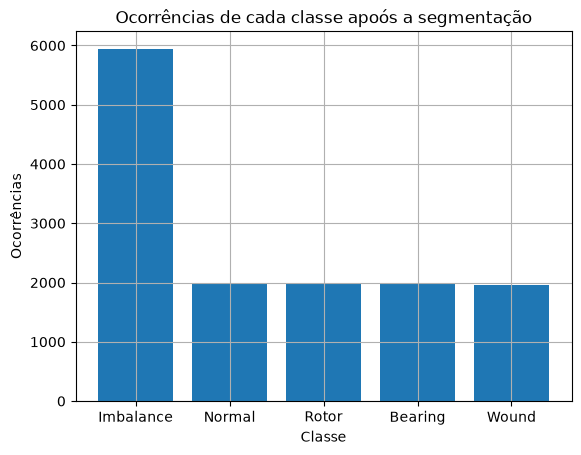

In [6]:
data = df_features_dataset['class'].value_counts()
print(data.index)
plt.figure()
plt.bar(data.index, data.values)
plt.grid()
plt.xlabel("Classe")
plt.ylabel('Ocorrências')
plt.title("Ocorrências de cada classe apoós a segmentação")
plt.show()

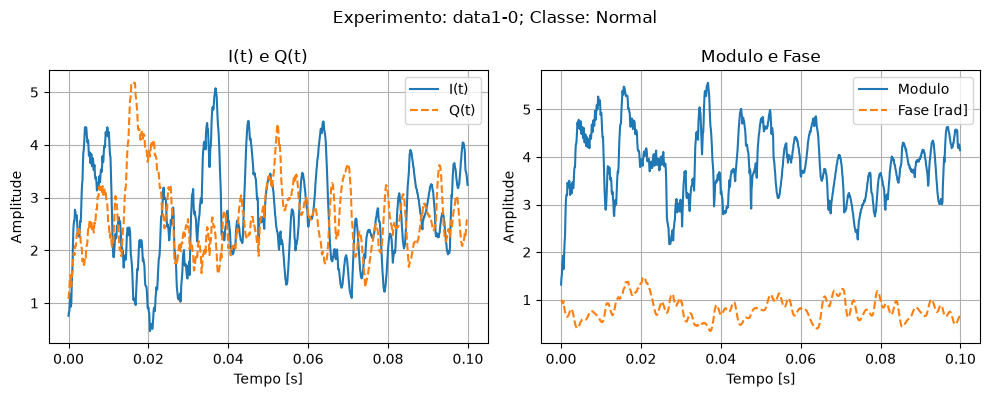

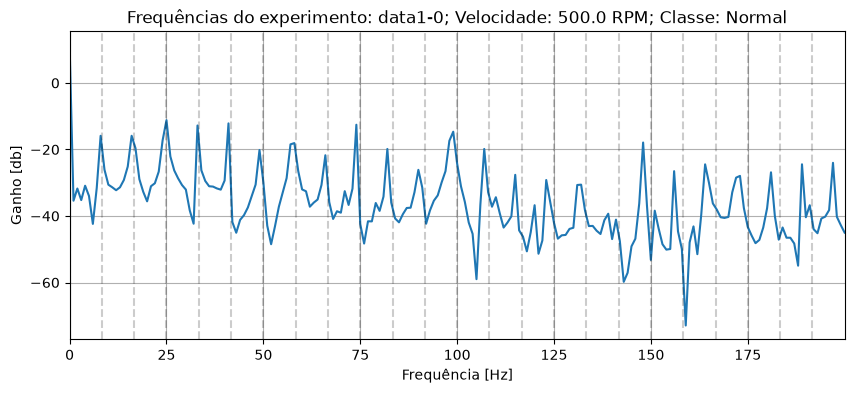

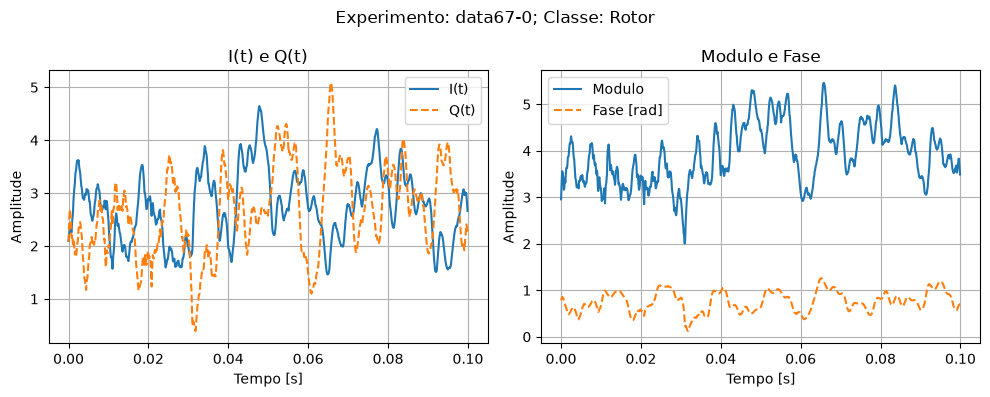

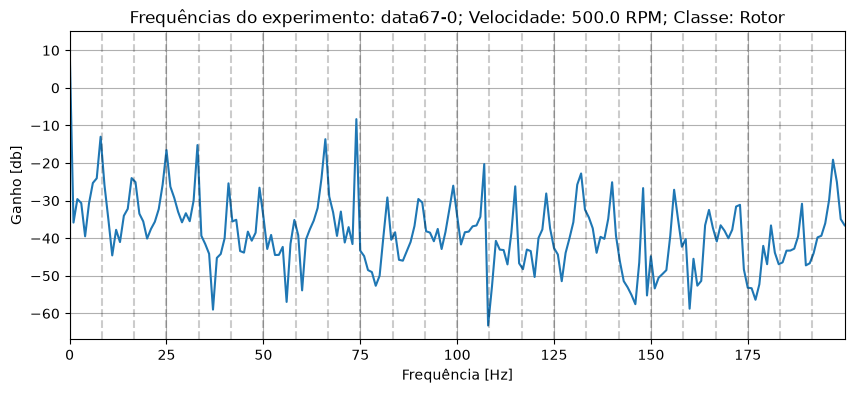

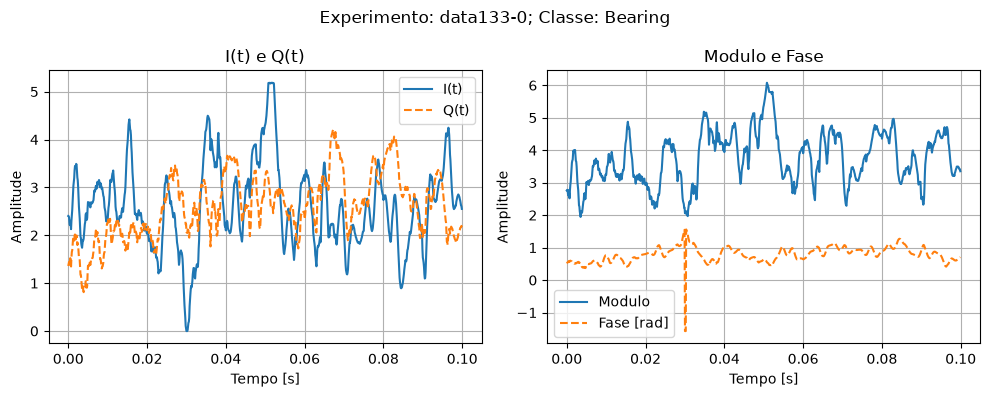

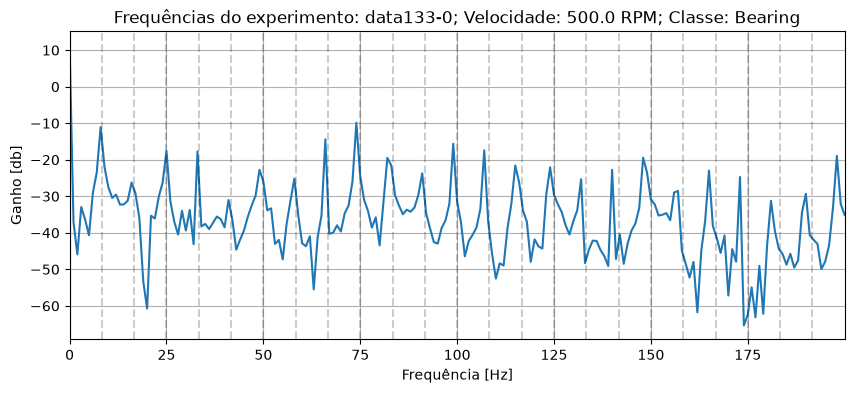

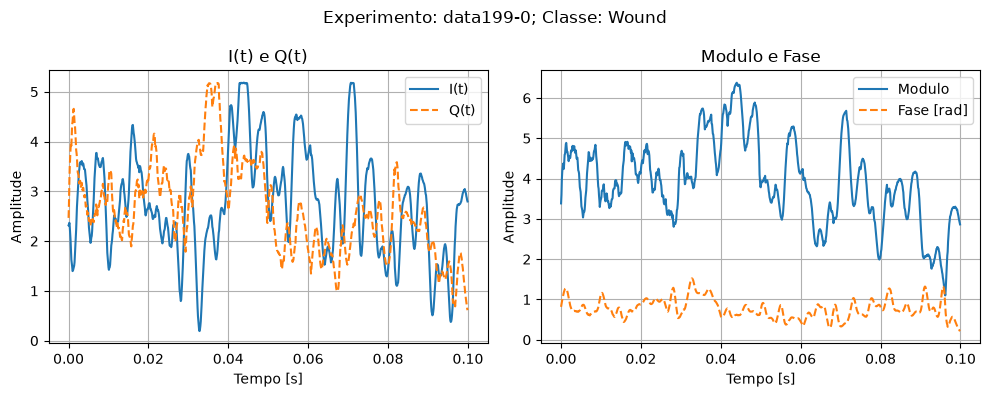

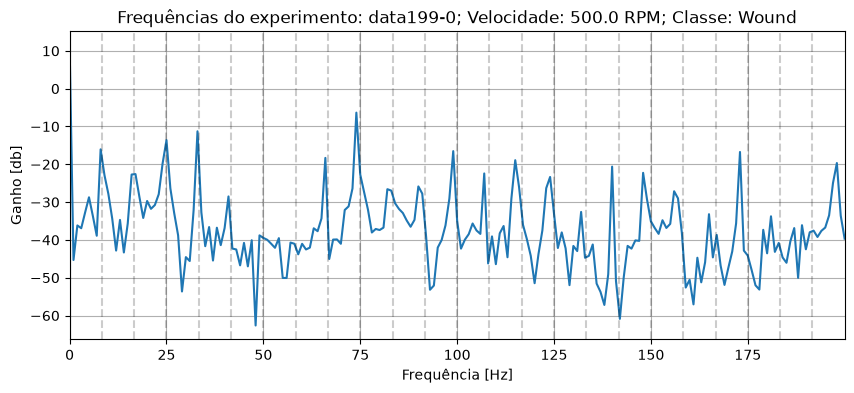

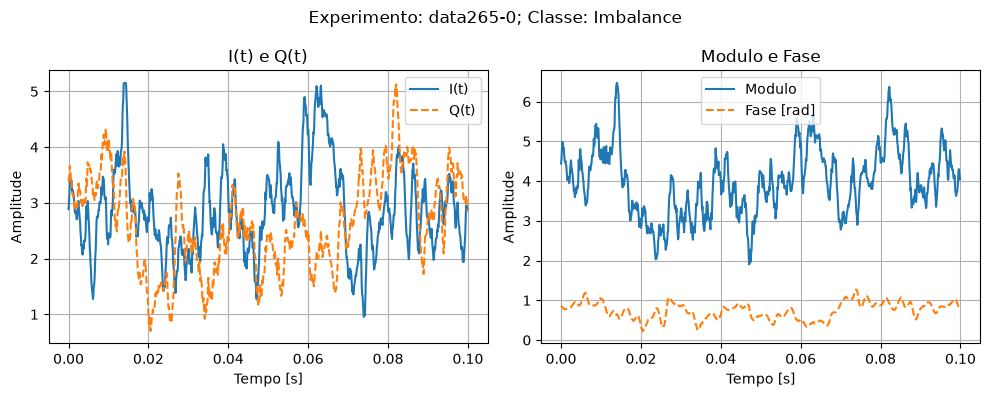

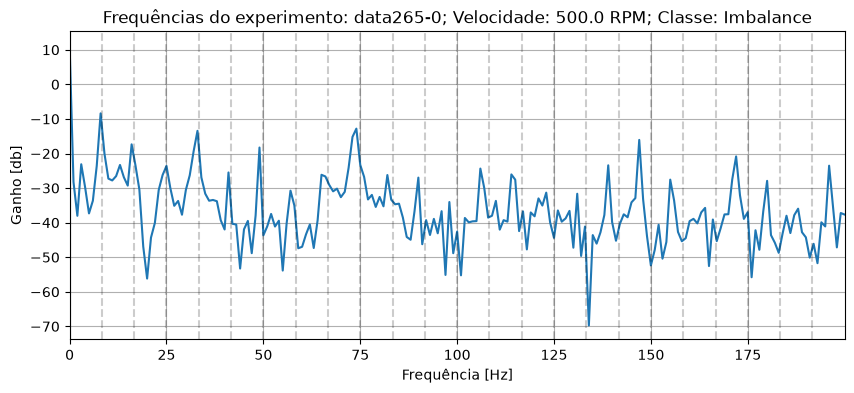

In [7]:
for c in df_features_dataset['class'].unique():
    data = df_features_dataset[df_features_dataset['class'] == c].iloc[0]
    raw_data = load_rawData(data['rawData'])
    #print(raw_data.head())

    tamanho = 1000
    x = np.arange(0, tamanho)
    fig, ax = plt.subplots(1,2, figsize=(10,4))
    ax[0].plot(x/10000, raw_data['I_data'].iloc[0:tamanho], markersize=2)
    ax[0].plot(x/10000, raw_data['Q_data'].iloc[0:tamanho], '--', markersize=2)
    ax[0].legend(["I(t)", "Q(t)"])
    ax[0].grid()
    ax[0].set_xlabel("Tempo [s]")
    ax[0].set_ylabel("Amplitude")
    ax[0].set_title("I(t) e Q(t)")


    ax[1].plot(x/10000, raw_data['module'].iloc[0:tamanho], markersize=2)
    ax[1].plot(x/10000, raw_data['fase'].iloc[0:tamanho], '--', markersize=1)
    ax[1].legend(["Modulo", "Fase [rad]"])
    ax[1].grid()
    ax[1].set_xlabel("Tempo [s]")
    ax[1].set_ylabel("Amplitude")
    ax[1].set_title("Modulo e Fase")

    # Título geral
    fig.suptitle("Experimento: " + data['dataName'] + "; Classe: " + c)

    plt.tight_layout()
    plt.show()

    max_frequency = 200
    f_data = freq(raw_data,max_frequency=max_frequency)
    
    plt.figure(figsize=(10,4))
    plt.plot(f_data[0], f_data[1], markersize=2)
    for f in data['motorSpeed']/60*np.arange(max_frequency/(data['motorSpeed']/60)):
        plt.axvline(x=f, linestyle='--', color="black", alpha=0.2, markersize=1)
    plt.xlim(f_data[0][0], f_data[0][-1])
    plt.grid()
    plt.xlabel("Frequência [Hz]")
    plt.ylabel("Ganho [db]")
    plt.title("Frequências do experimento: " + data['dataName'] + "; Velocidade: " + str(data['motorSpeed']) + " RPM; Classe: " + c)
    plt.show()


<H1>Analise exploratória das Features</H1>

In [8]:

time_columns = [ 'I_amplitude',
       'I_energy', 'I_kurtosis', 'I_max', 'I_mean', 'I_median', 'I_min',
       'I_mode', 'I_rms', 'I_skewness', 'I_std', 'I_variance', 'Q_amplitude',
       'Q_energy', 'Q_kurtosis', 'Q_max', 'Q_mean', 'Q_median', 'Q_min',
       'Q_mode', 'Q_rms', 'Q_skewness', 'Q_std', 'Q_variance',
       'module_amplitude', 'module_energy', 'module_kurtosis', 'module_max',
       'module_mean', 'module_median', 'module_min', 'module_mode',
       'module_rms', 'module_skewness', 'module_std', 'module_variance',
       'fase_amplitude', 'fase_energy', 'fase_kurtosis', 'fase_max',
       'fase_mean', 'fase_median', 'fase_min', 'fase_mode', 'fase_rms',
       'fase_skewness', 'fase_std', 'fase_variance']

time_columns_removidas = ["I_mean", "Q_mean", "Q_median", "Q_rms", "module_energy",
"module_mean", "module_median", "module_rms", "fase_std",
"fase_variance",
"fase_median",
"Q_variance",
"Q_energy",
"I_rms", "I_energy"]

freq_columns = ['fft_bandwidth',
       'fft_dominant_frequency', 'fft_dominant_frequency_magnitude',
       'fft_energy_spectral', 'fft_frequency_mean', 'fft_frequency_median',
       'fft_kurtosis', 'fft_skewness']

freq_columns_removidas = ['fft_dominant_frequency', 'fft_dominant_frequency_magnitude', 'fft_energy_spectral']

class_column = ['class']

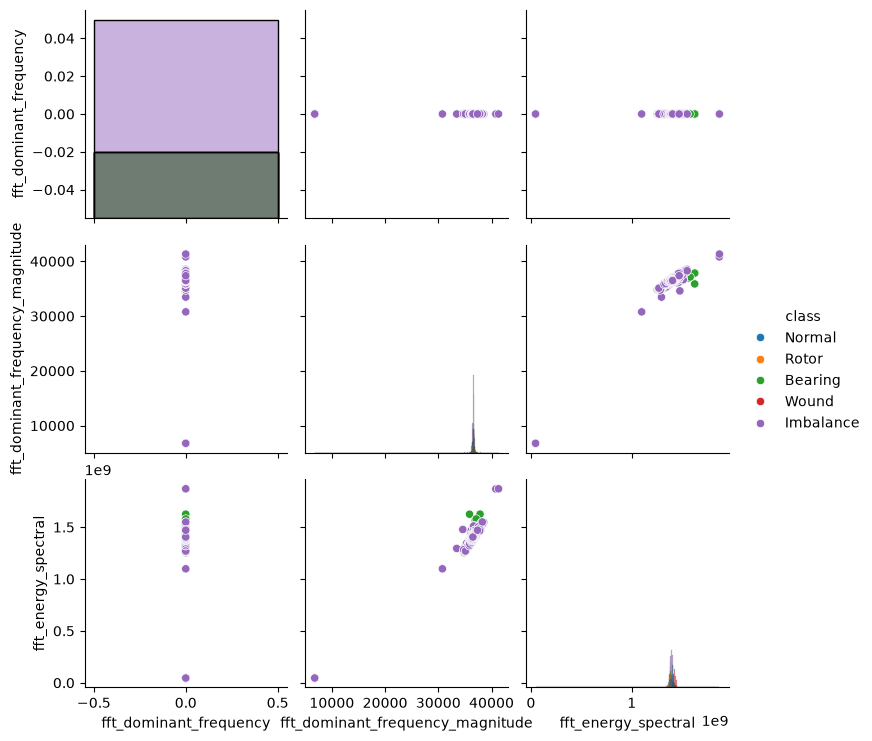

In [9]:
sns.pairplot(
    data = df_features_dataset[freq_columns_removidas + class_column],
    hue=class_column[0],
    diag_kind="hist"
)
plt.grid()
plt.show()

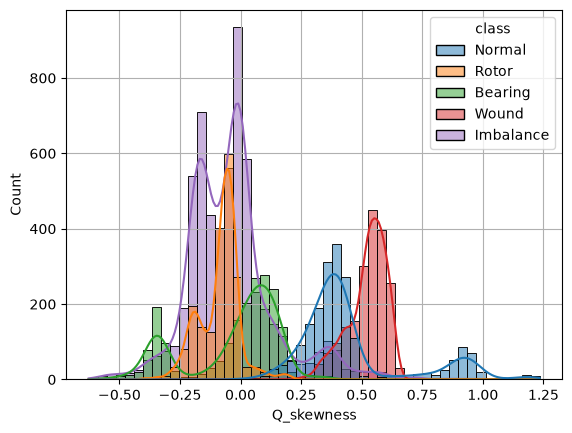

In [18]:
sns.histplot(
    data=df_features_dataset,
    x='Q_skewness',
    hue=class_column[0],
    kde=True
)

plt.grid()
plt.show()

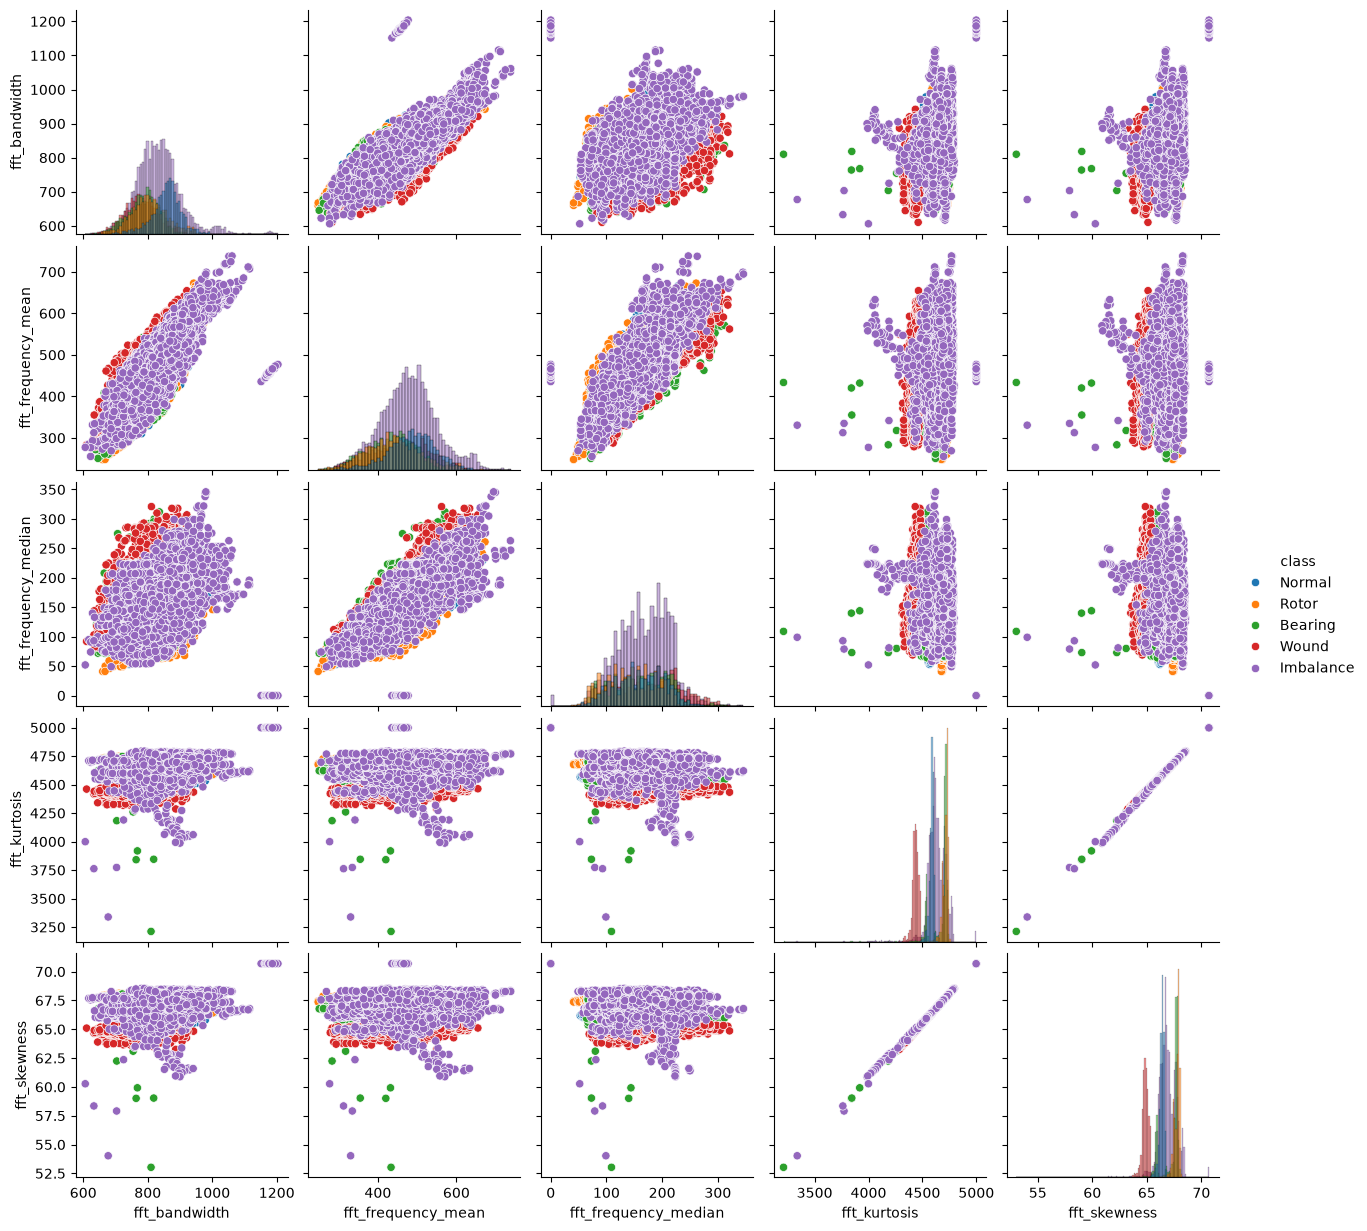

In [ ]:
freq_columns_filtradas = [
    col for col in freq_columns
    if col not in freq_columns_removidas
]

sns.pairplot(
    data = df_features_dataset[freq_columns_filtradas + class_column],
    hue=class_column[0],
    diag_kind="hist"
)

plt.show()

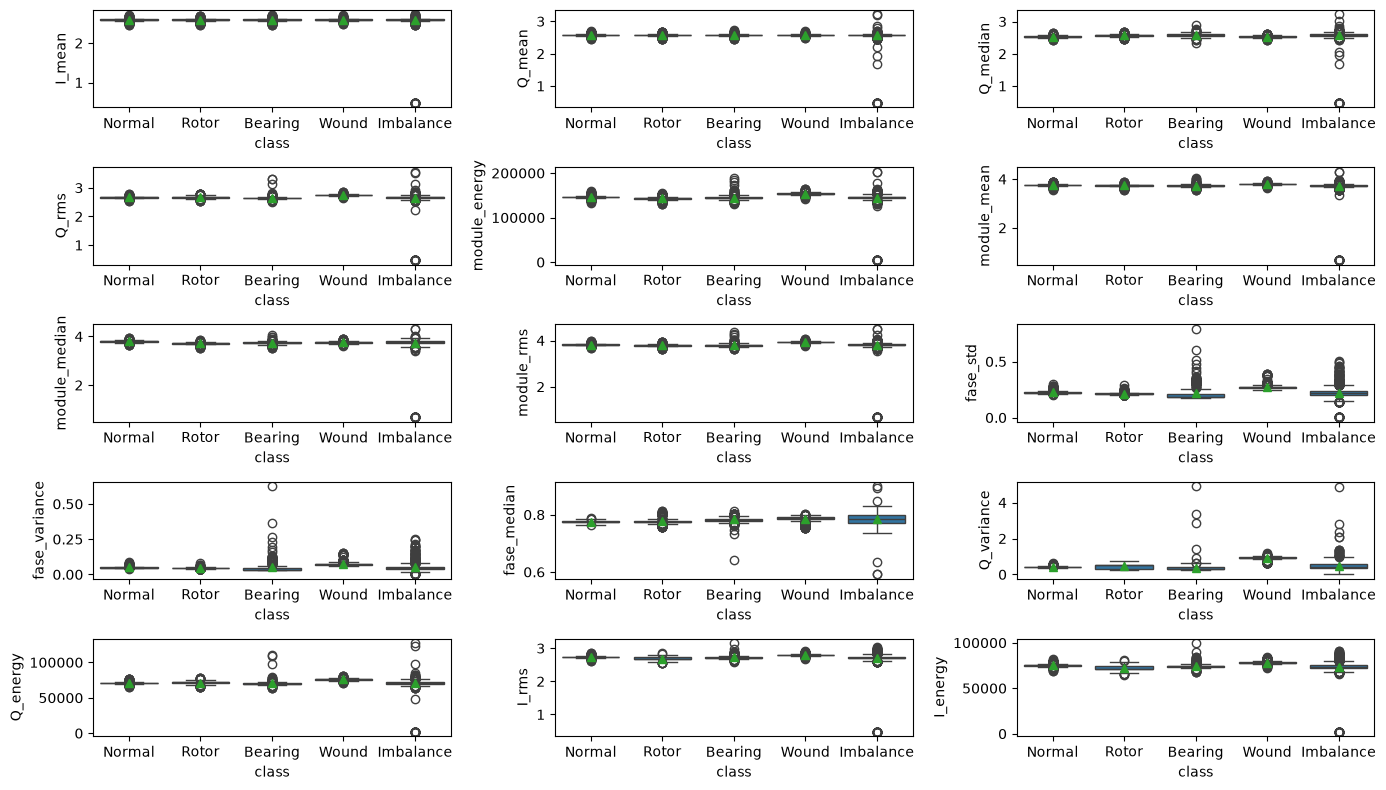

In [ ]:
shape = (int(np.ceil(len(time_columns_removidas)/3)),3)
fig, axes = plt.subplots(shape[0], shape[1], figsize=(14,8))
i = 0
for column in time_columns_removidas:
    sns.boxplot(
        data=df_features_dataset,
        x=class_column[0],
        y=column,
        showmeans=True,
        ax=axes.flat[i]
    )
    i = i+1

# Remove os eixos que não foram utilizados
for i in range(len(time_columns_removidas), shape[0]*shape[1]):
    fig.delaxes(axes.flat[i])

plt.tight_layout()
plt.show()

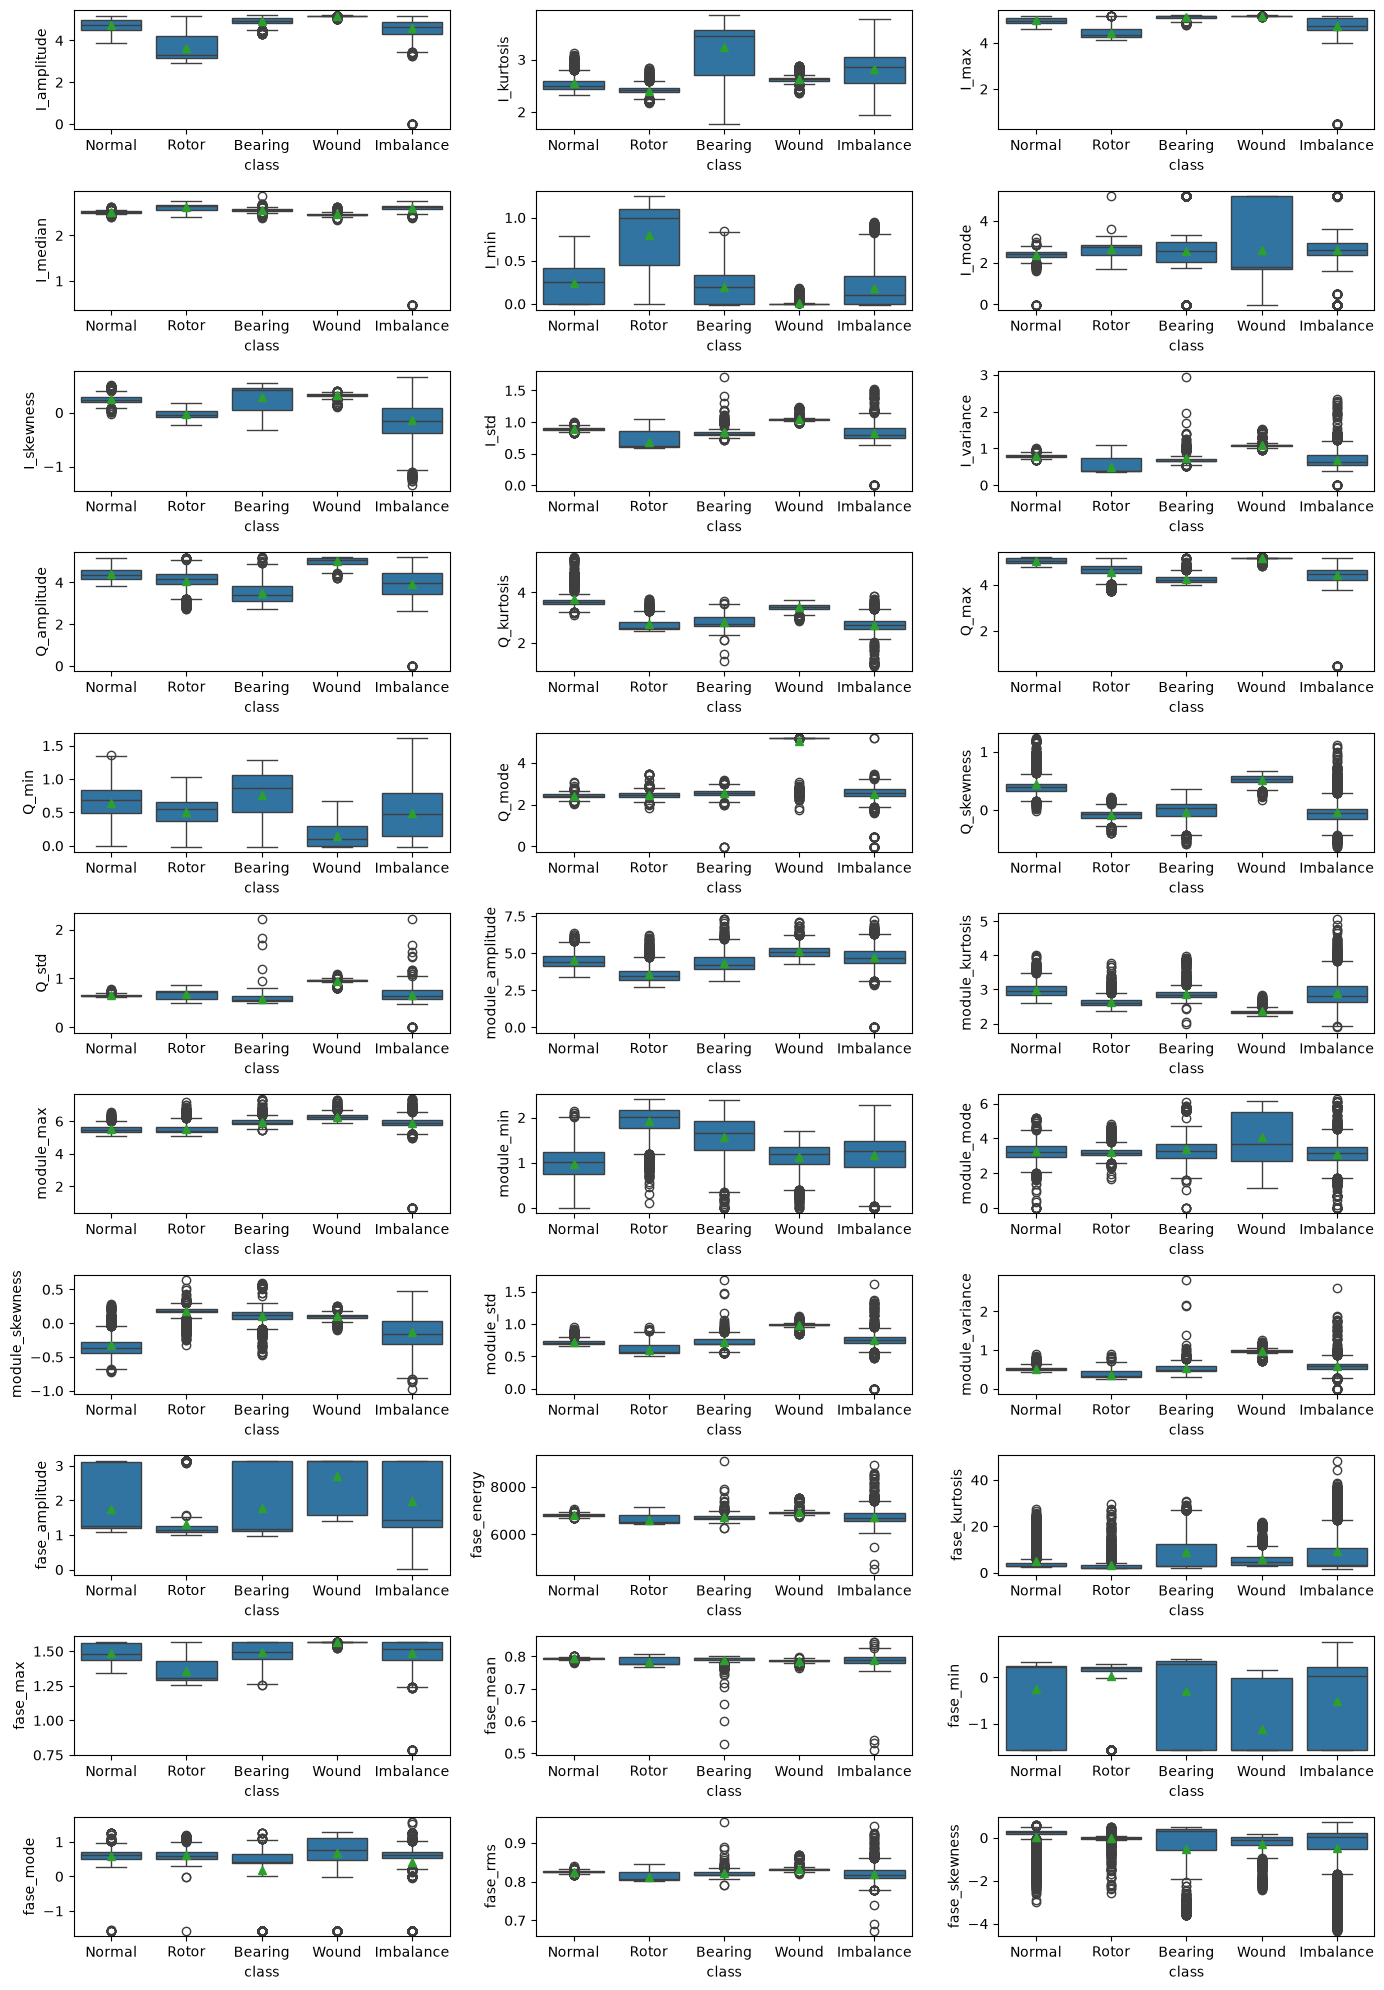

In [ ]:
time_columns_filtradas = [
    col for col in time_columns if col not in time_columns_removidas
]

shape = (int(np.ceil(len(time_columns_filtradas)/3)),3)

fig, axes = plt.subplots(shape[0], shape[1], figsize=(14,20))
i = 0
for column in time_columns_filtradas:
    sns.boxplot(
        data=df_features_dataset,
        x=class_column[0],
        y=column,
        showmeans=True,
        ax=axes.flat[i]
    )
    i = i+1

# Remove os eixos que não foram utilizados
for i in range(len(time_columns_filtradas), shape[0]*shape[1]):
    fig.delaxes(axes.flat[i])

plt.tight_layout()
plt.show()

I_amplitude


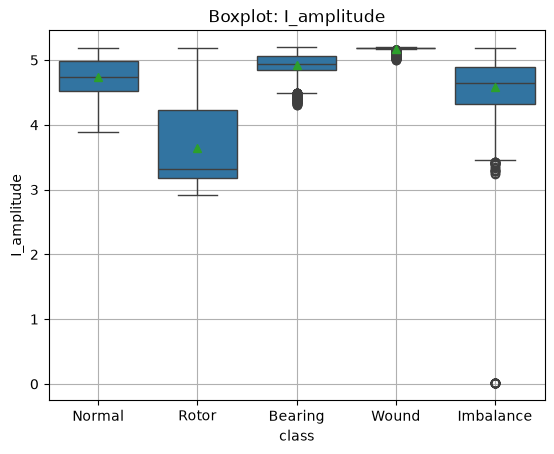

I_energy


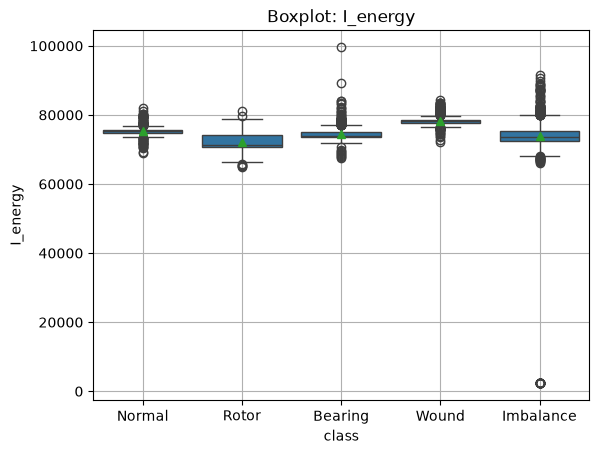

I_kurtosis


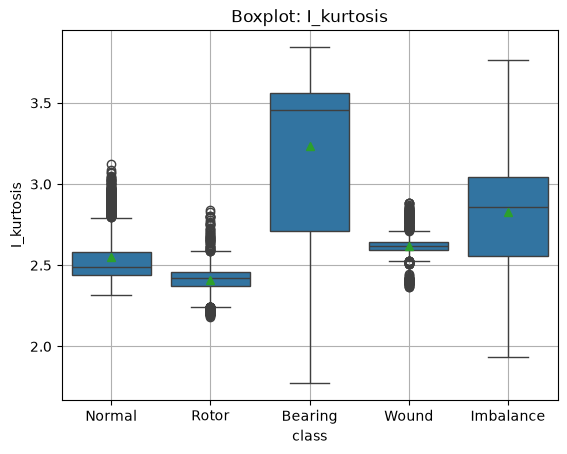

I_max


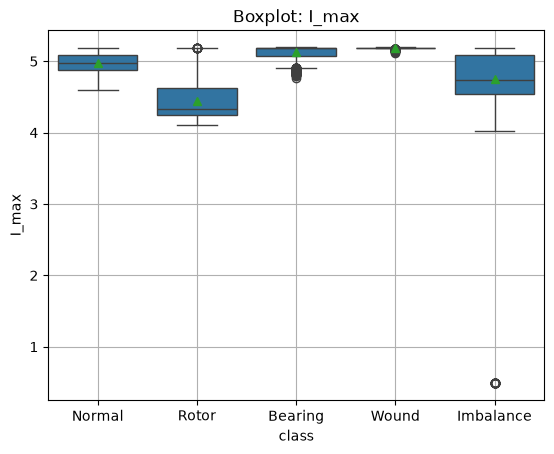

I_mean


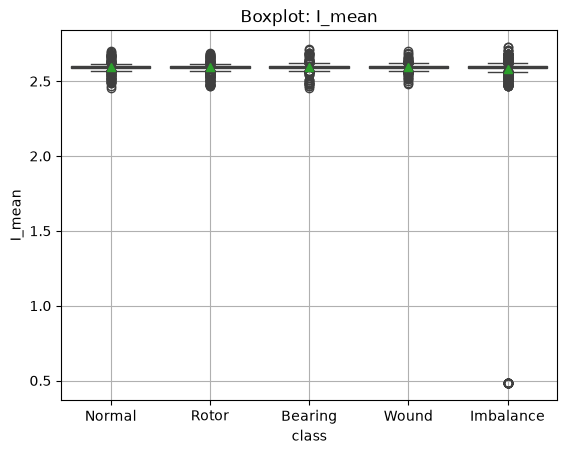

I_median


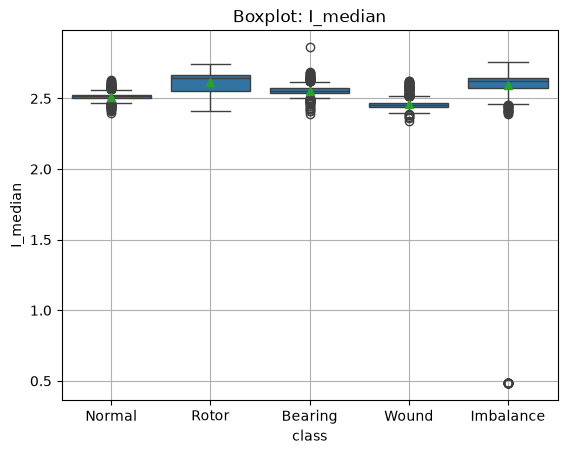

I_min


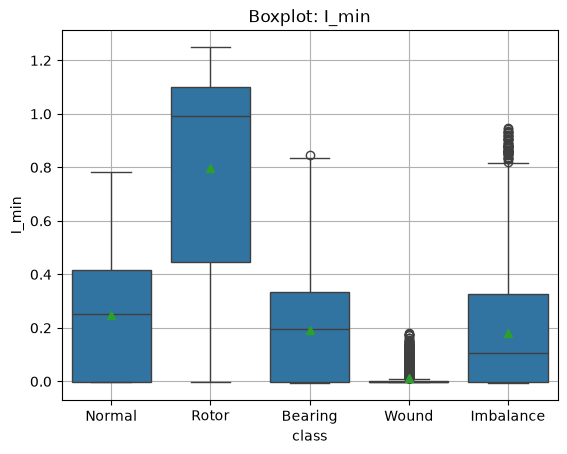

I_mode


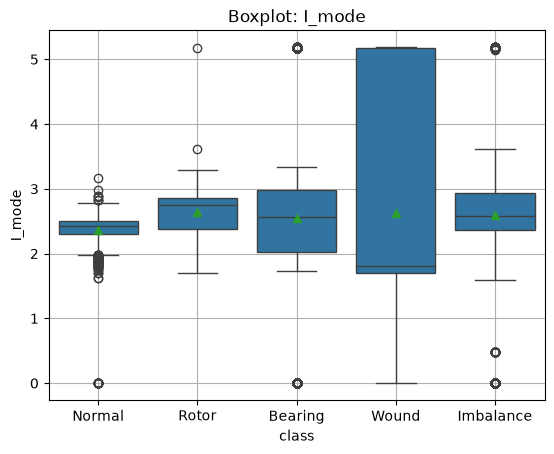

I_rms


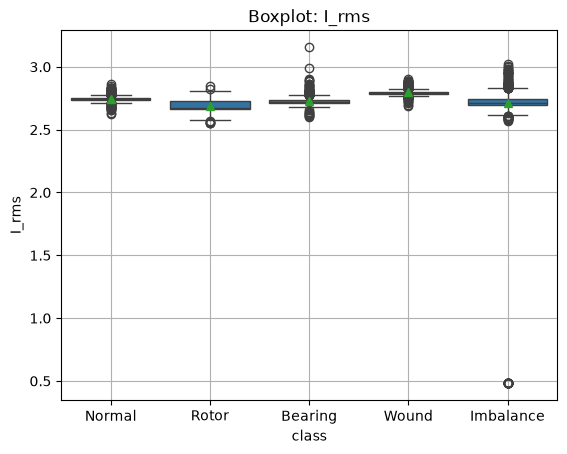

I_skewness


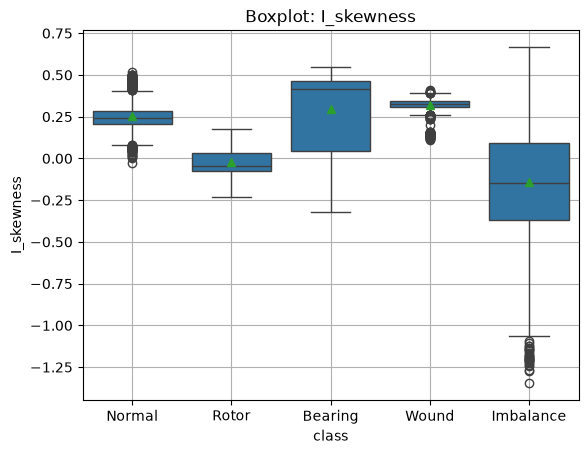

I_std


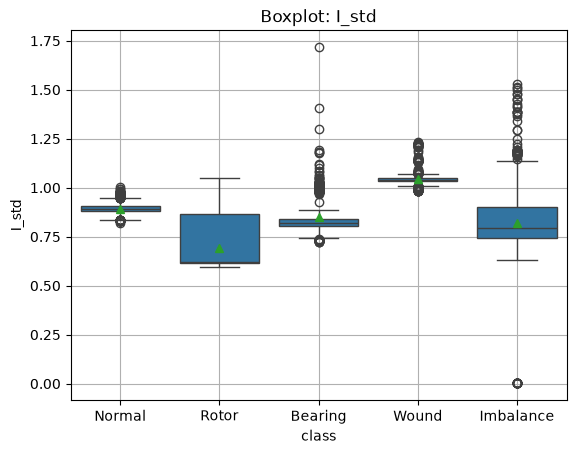

I_variance


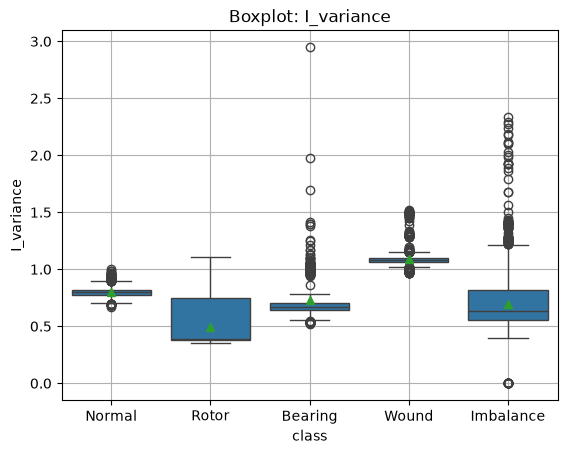

Q_amplitude


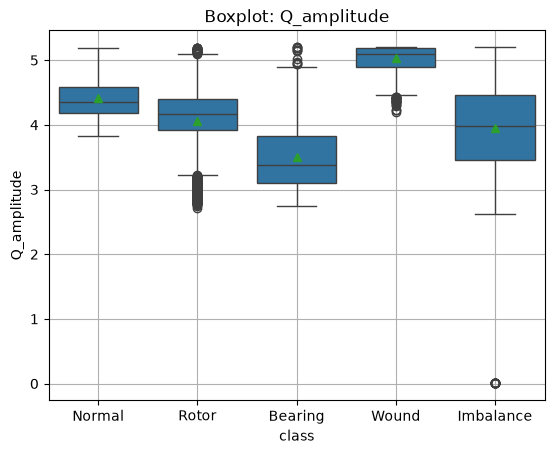

Q_energy


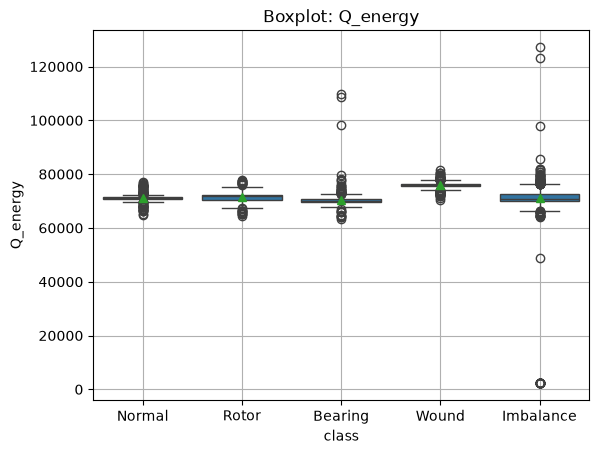

Q_kurtosis


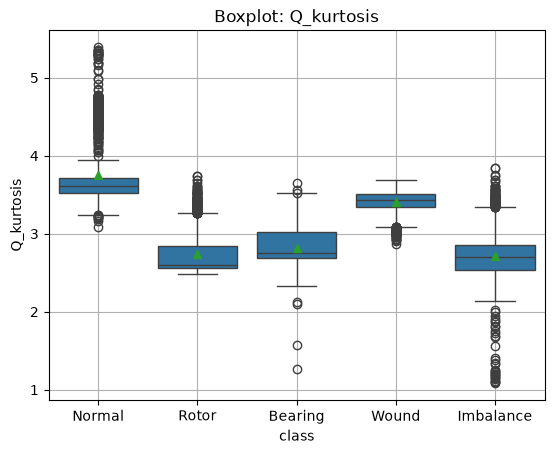

Q_max


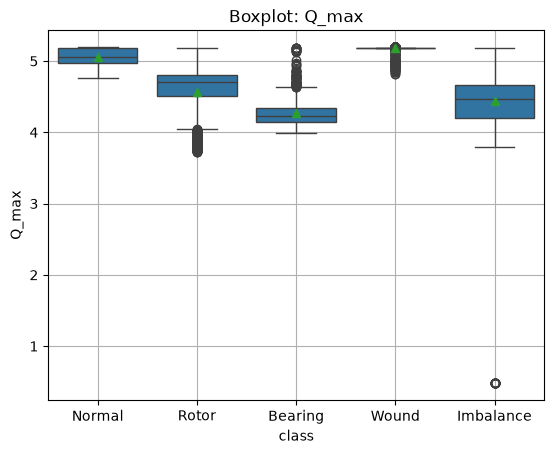

Q_mean


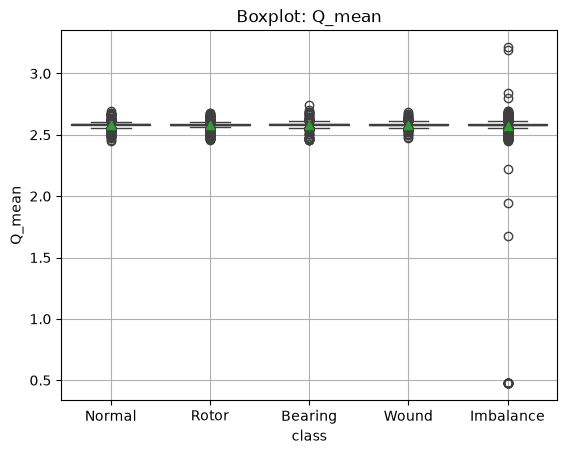

Q_median


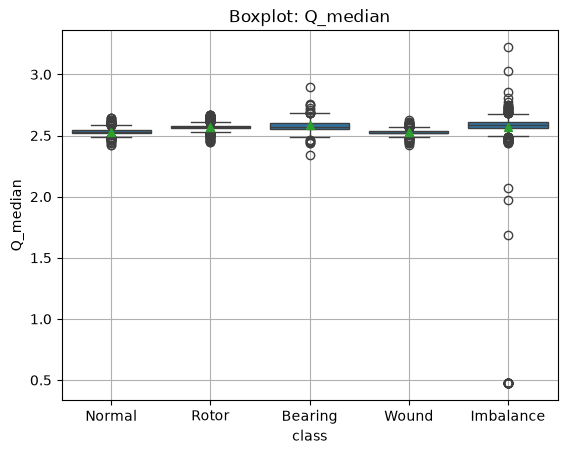

Q_min


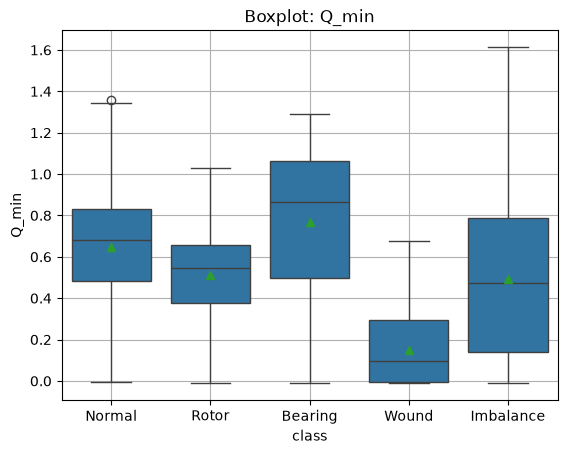

Q_mode


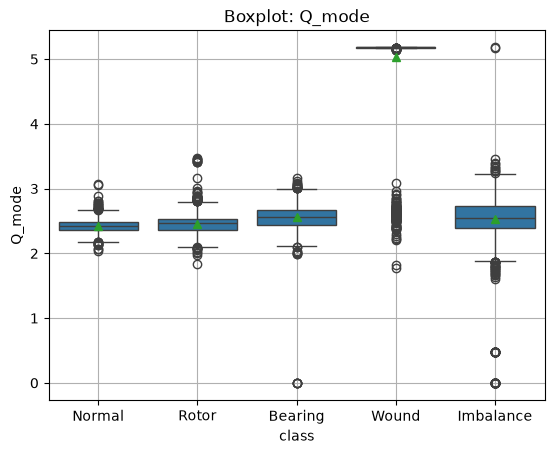

Q_rms


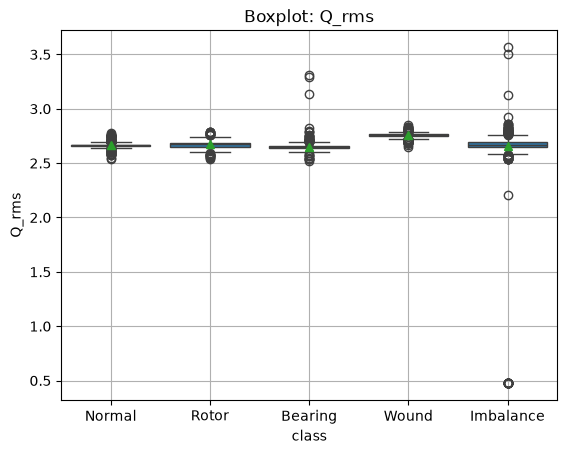

Q_skewness


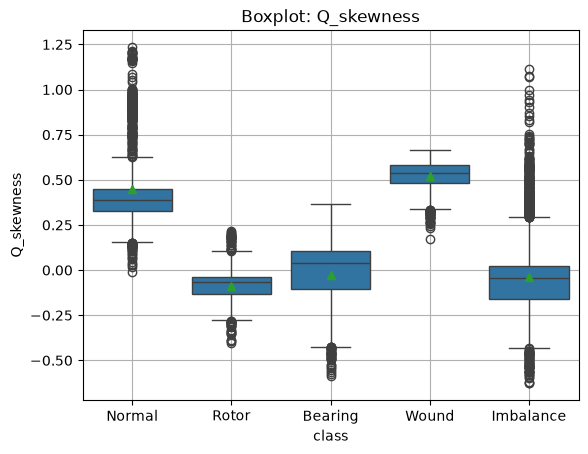

Q_std


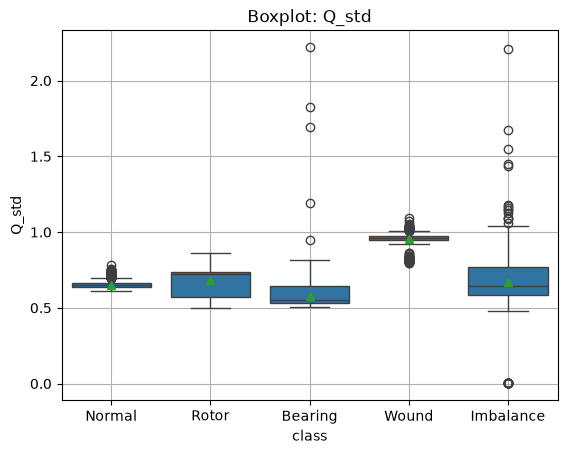

Q_variance


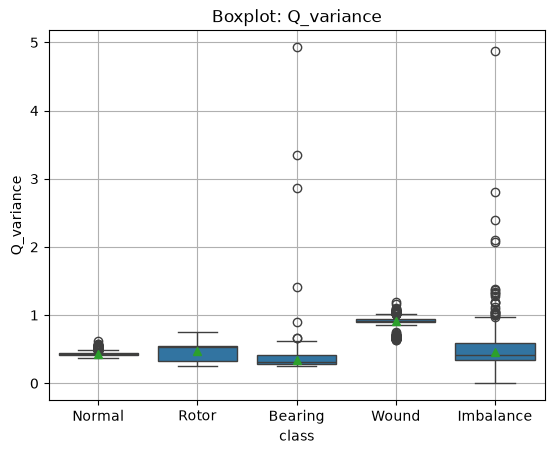

module_amplitude


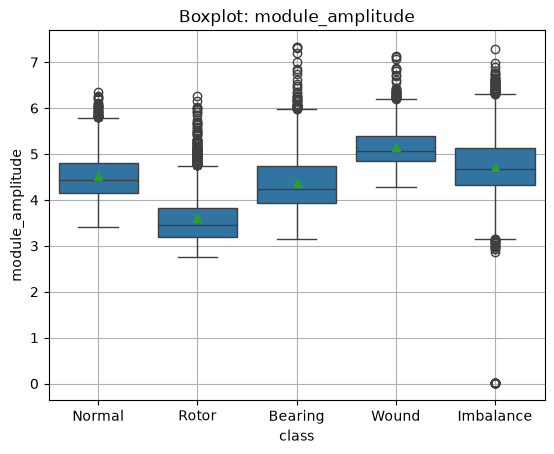

module_energy


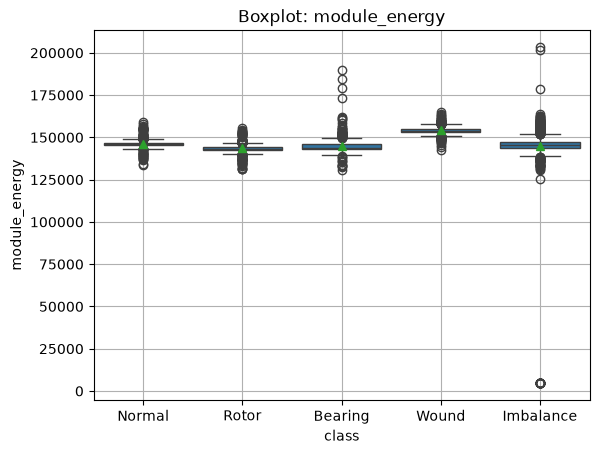

module_kurtosis


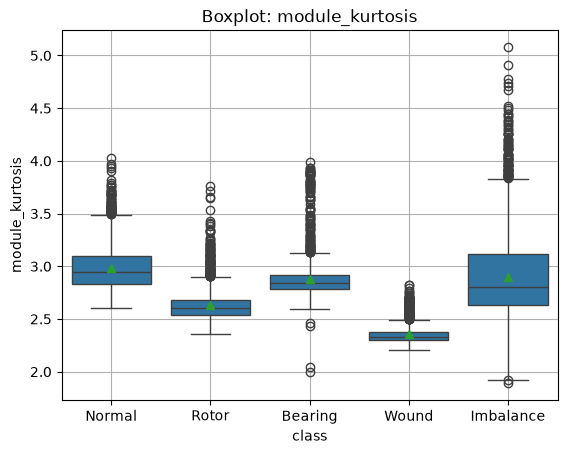

module_max


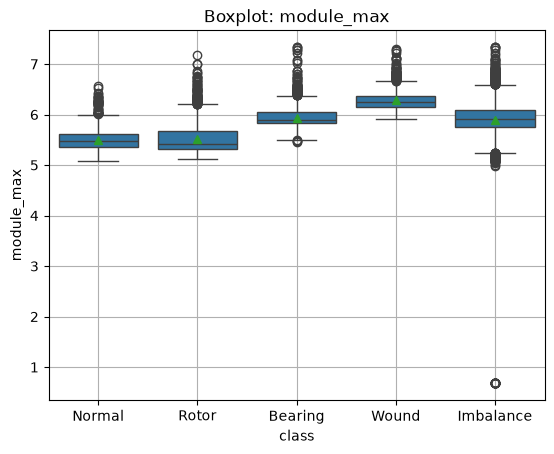

module_mean


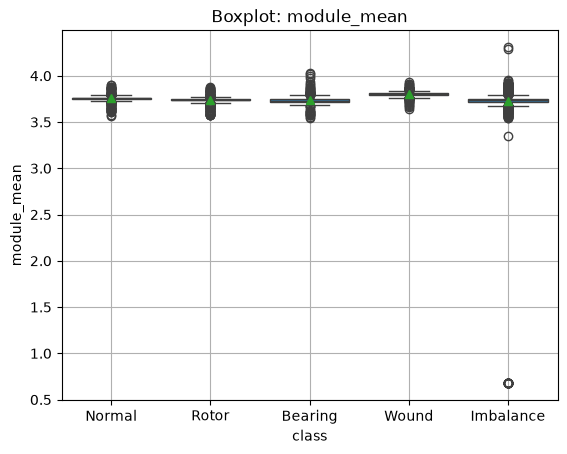

module_median


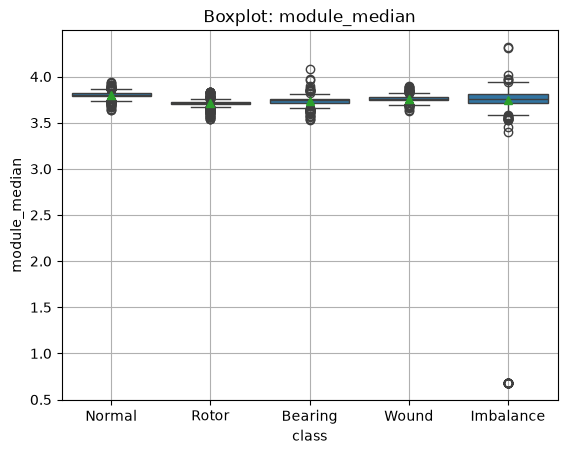

module_min


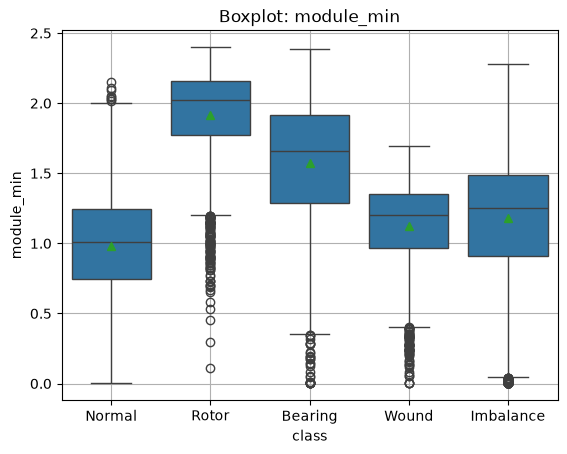

module_mode


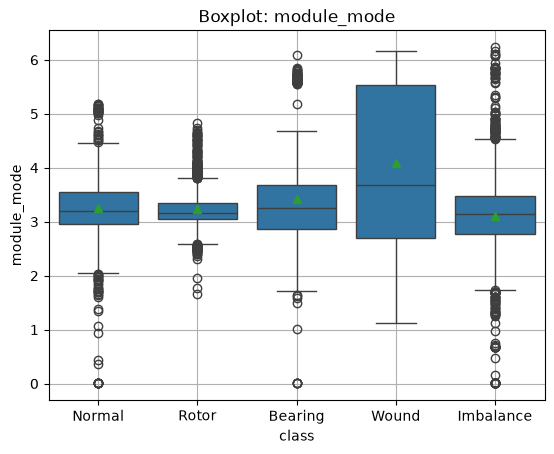

module_rms


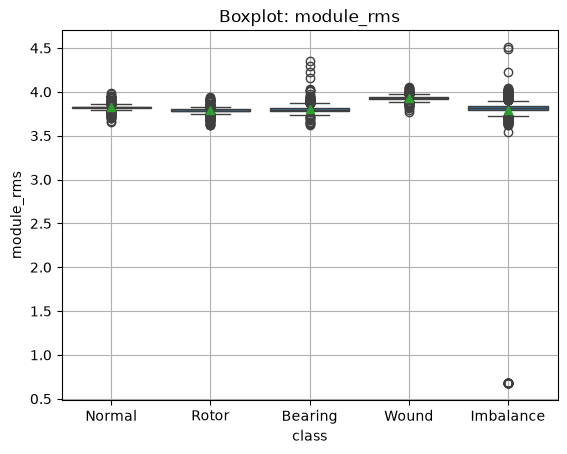

module_skewness


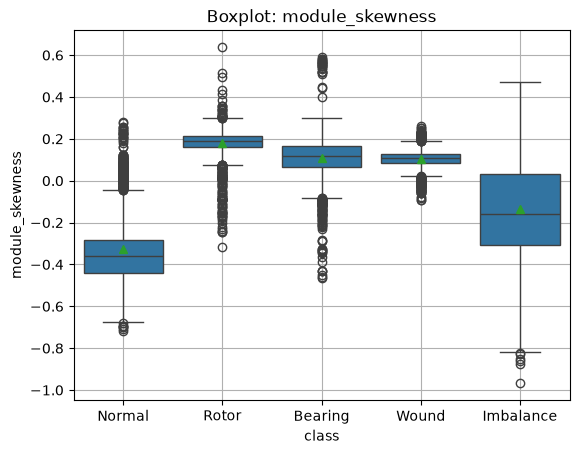

module_std


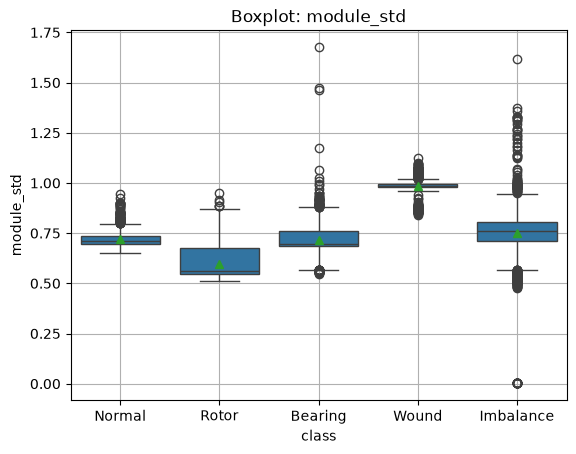

module_variance


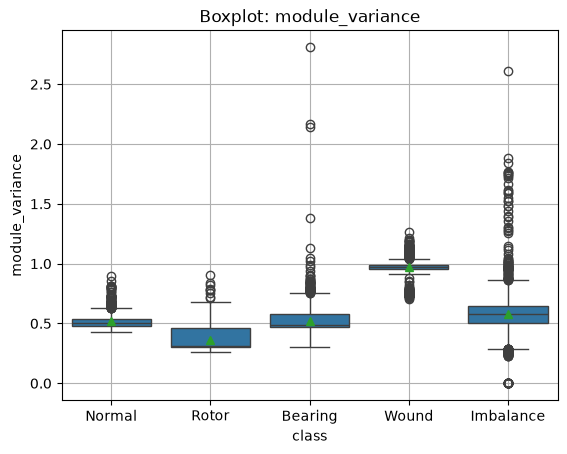

fase_amplitude


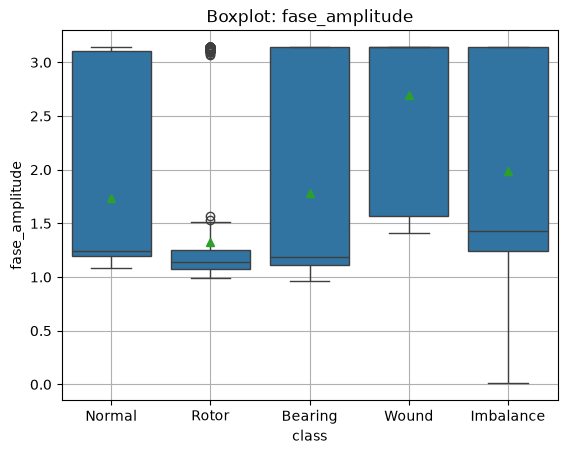

fase_energy


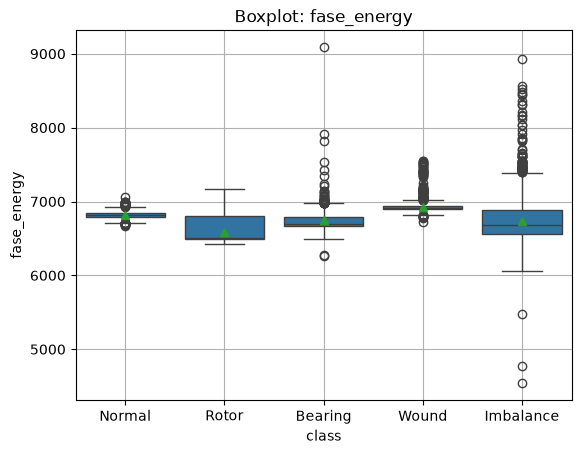

fase_kurtosis


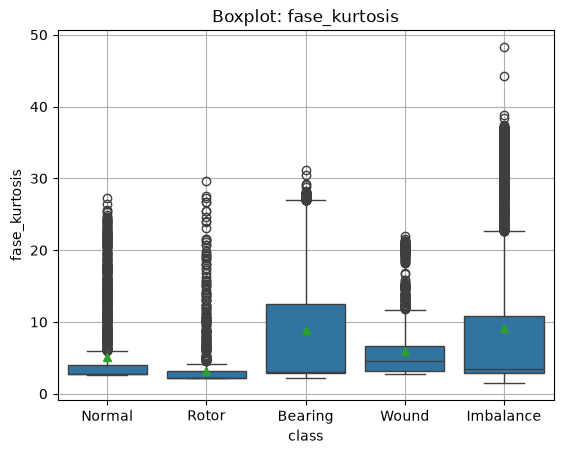

fase_max


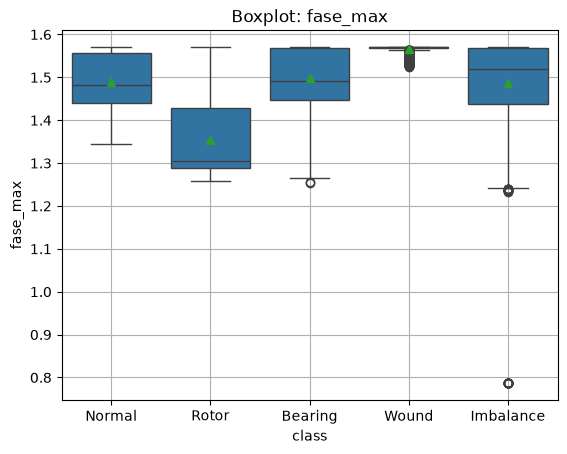

fase_mean


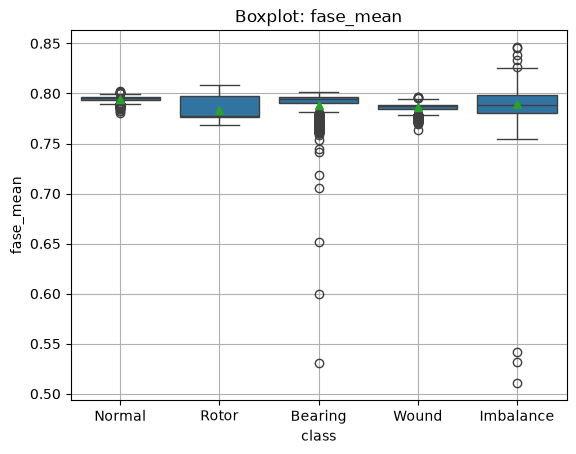

fase_median


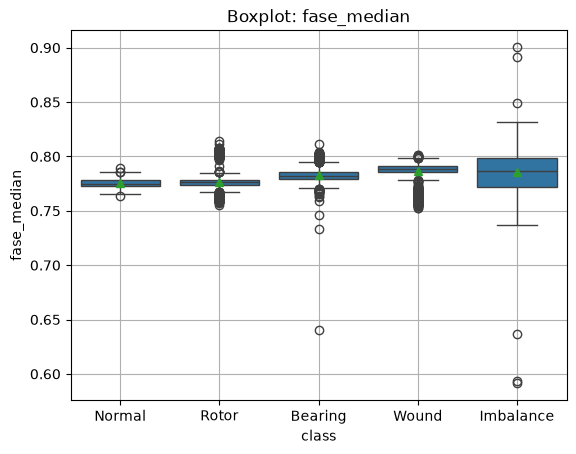

fase_min


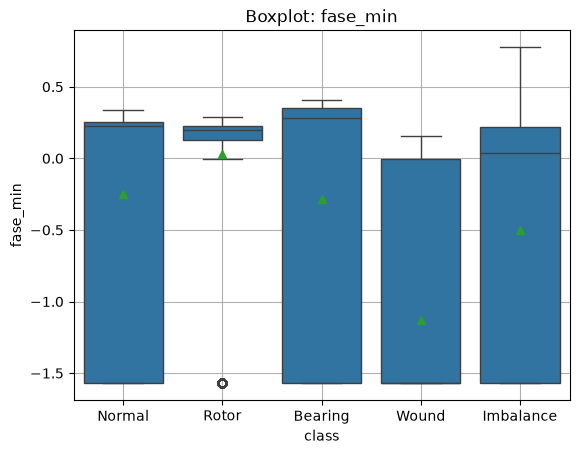

fase_mode


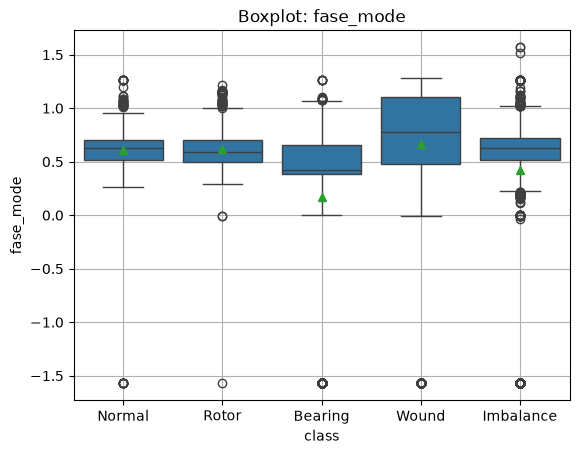

fase_rms


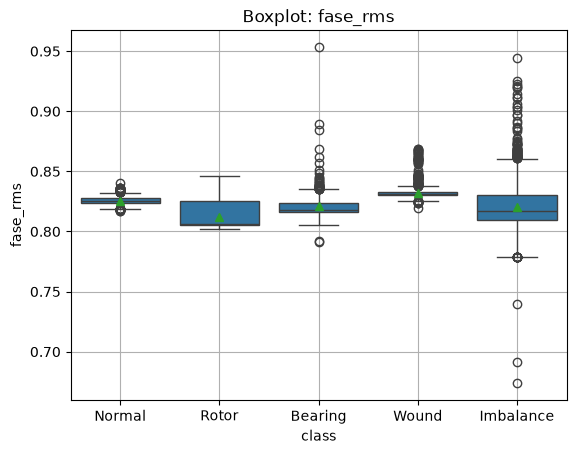

fase_skewness


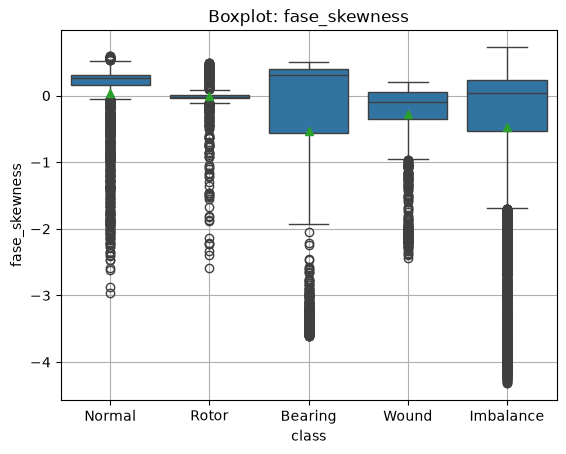

fase_std


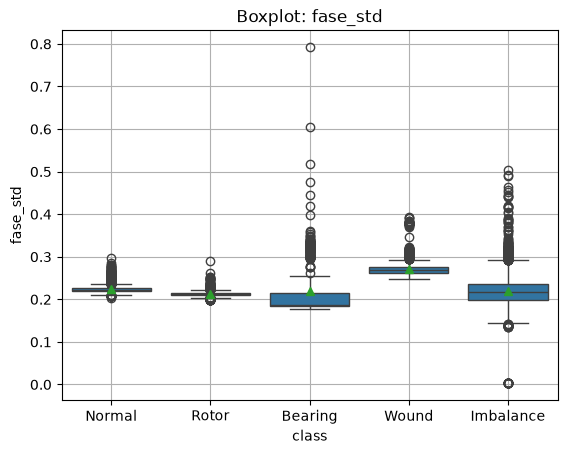

fase_variance


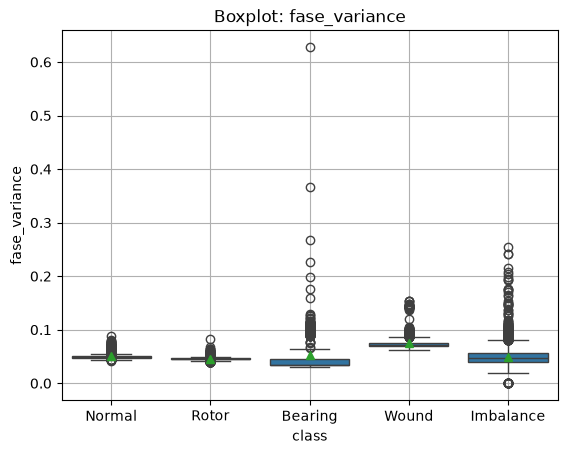

In [ ]:
for column in time_columns:
    sns.boxplot(
        data=df_features_dataset,
        x=class_column[0],
        y=column,
        showmeans=True
    )
    print(column)
    plt.grid(True)
    plt.title(f'Boxplot: {column}')
    plt.show()

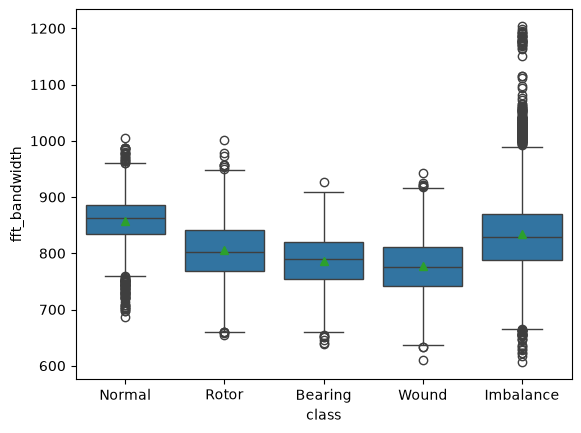

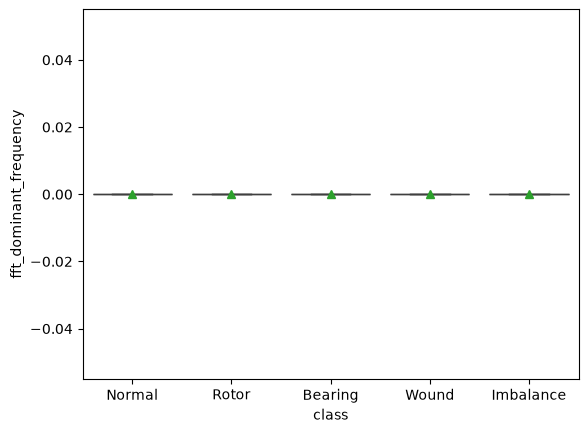

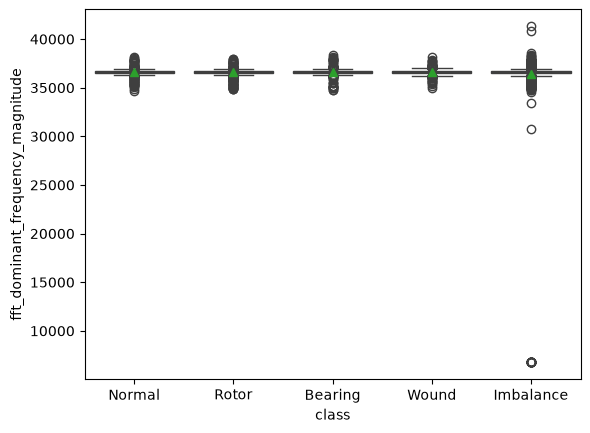

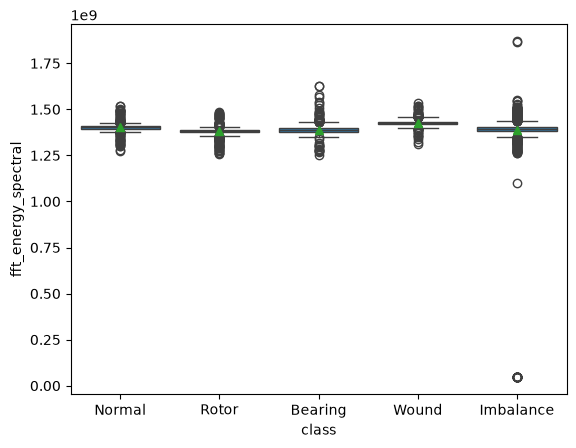

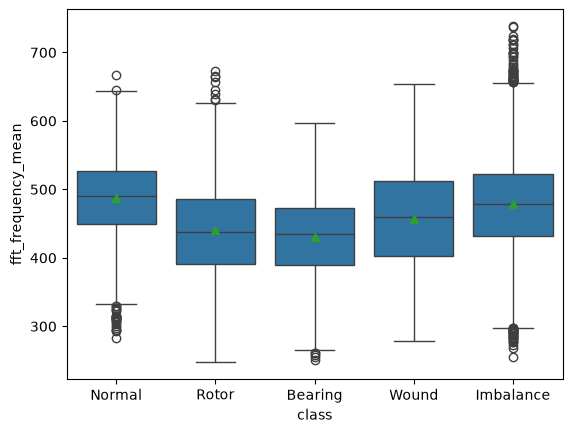

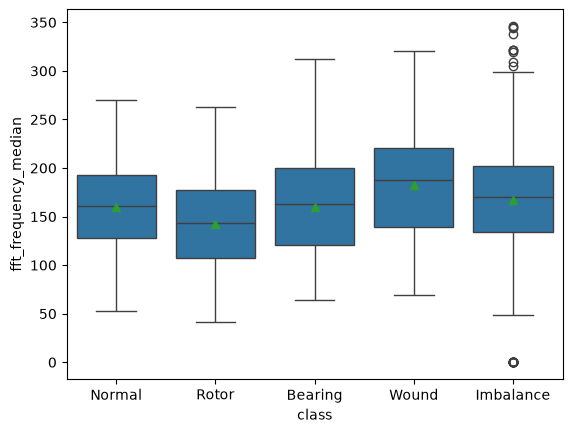

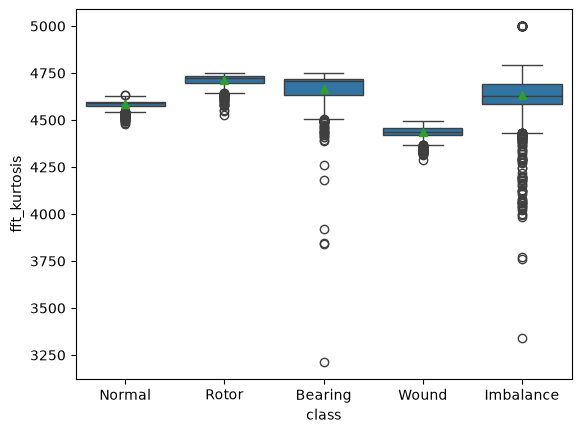

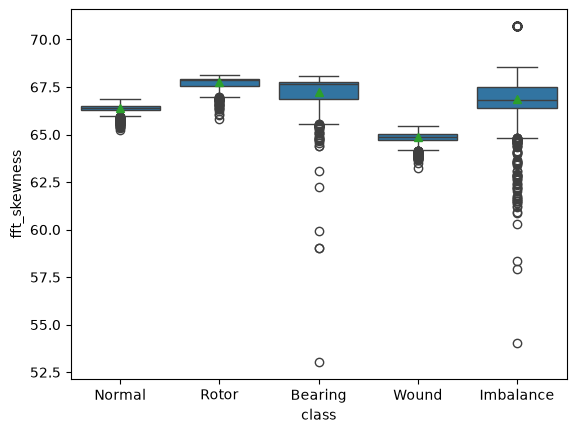

In [ ]:
for column in freq_columns:
    sns.boxplot(
        data=df_features_dataset,
        x=class_column[0],
        y=column,
        showmeans=True
    )
    plt.show()

['zaa', 'sad']
